# Band structures: DFT and Wannier-interpolated (Y₂Ir₂O₇)

DFT bands (pw.x `calculation='bands'`) with Wannier-interpolated bands drawn over them at the same k-points. A
**compute** cell (settings at the top; builds and diagonalises each Wannier model once, saving the
eigenvalues to `<BANDS_IN folder>/wannier_eigs/`, then reads them back) and a **plot** cell (plot settings at the top;
only draws, so it can be edited and re-run freely).

**k-points and coordinates.**
* The path is the `K_POINTS crystal_b` block of `BANDS_IN`, expanded by `read_kpath` exactly as pw.x expands it: `n`
  points per segment from each node, the last node once. These are **reduced** coordinates in the basis b1, b2, b3 of
  that input's `CELL_PARAMETERS` (b_i·a_j = 2π δ_ij).
* `model.solve_ham(points)` takes reduced k in the basis of the `.win` cell (`W90.lat`); the compute cell checks the two
  cells are the same rows in the same order (otherwise a reduced k would be a different point).
* pw.x prints the `bands.out` k in **Cartesian** units of 2π/alat; the compute cell converts them back
  (k_red,i = k·a_i / alat) and checks them against the path point for point.
* x axis: cumulative |Δk| in Å⁻¹ (2π included), Wannier90's `_band.dat` convention (QE's `bands.x`/`plotband.x` use
  2π/alat units instead: the same picture scaled by alat/2π).

**Wannier model** (`MODEL_SOURCE`): `"chk"` is the production model dθ uses (`axion_phonon.wannier.run_model`, the
H(R) of `pair_models`): H(R) at full precision from the `.chk` + `.eig`, folded onto Wigner-Seitz images on the run's
centres, or on the atoms with `PIN_TO_ATOMS` (MnBi2Te4, bug #21); no hopping cut. `"hr_dat"` is PythTB's reading of
`_hr.dat` (Wannier90's own images). Windows from `W90` (`dis_window`, `dis_froz_window`); mesh from the `.chk`.

**What to expect.** Inside the frozen window every DFT band is a Wannier band (exactly at the mesh k, closely between).
Above it the Wannier bands are the projected Hamiltonian of the trial orbitals in the outer window (projection only,
`dis_num_iter = 0`) and need not follow any DFT band, even at the mesh k (the `.eig` dots).

The two-material paper figure is `../figures/fig3.ipynb`.


In [1]:
import re
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "axion_phonon/axion.py").exists())
DATA = ROOT / "data"
# pythtb checkout, on the `external` branch (W90.model(orb_vecs=...), W90.dis_window)
PYTHTB = Path("/Users/treycole/Repos/pythtb")
sys.path.insert(0, str(PYTHTB))
sys.path.insert(0, str(ROOT))
from pythtb import W90
from axion_phonon.io.qe import read_bands_out, read_kpath, fermi_energy
from axion_phonon import wannier
from axion_phonon.io import wannier90

BOHR = 0.529177210903   # Angstrom

In [2]:
# ---- settings
PREFIX = "Y2Ir2O7"
BANDS_IN = DATA / "Y2Ir2O7/dft/base/bands/out/Y2Ir2O7.bands.in"            # k-path (K_POINTS crystal_b) and cell
BANDS_OUT = DATA / "Y2Ir2O7/dft/base/bands/out/Y2Ir2O7.bands.out"          # DFT bands, job 214641 (None: none)
SCF_OUT = DATA / "Y2Ir2O7/dft/base/scf/out/Y2Ir2O7.scf.out"                # Fermi level (SCF 213998, conv_thr 1e-10)
WANNIER = {                                                                # {label: Wannier90 run folder}
    "220455 production (f12.422_w22.644)": DATA / "Y2Ir2O7/windows/f12.422_w22.644_k8/base/out",
}
PIN_TO_ATOMS = True       # production: True (pair_models pins both materials; YIO since 10-26)
MODEL_SOURCE = "chk"      # "chk" (production H(R)) | "hr_dat" (PythTB reading _hr.dat)
# ---------------

# ---- k-path: reduced coordinates in the basis of BANDS_IN's CELL_PARAMETERS, expanded as pw.x does
points, ticks = read_kpath(BANDS_IN)                       # (nk, 3), [(index, label)]
lines = BANDS_IN.read_text().splitlines()
c = next(i for i, line in enumerate(lines) if line.strip().upper().startswith("CELL_PARAMETERS"))
assert "angstrom" in lines[c].lower(), lines[c]
lattice = np.array([[float(v) for v in lines[c + j].split()[:3]] for j in (1, 2, 3)])   # rows a_i (Angstrom)
recip = 2 * np.pi * np.linalg.inv(lattice).T                                           # rows b_i (1/Angstrom)
distance = np.r_[0, np.cumsum(np.linalg.norm(np.diff(points @ recip, axis=0), axis=1))]  # x axis (1/Angstrom)
e_fermi = fermi_energy(SCF_OUT)
print(f"path {BANDS_IN.name}: {len(points)} k; E_F = {e_fermi} eV from {SCF_OUT.relative_to(DATA)}")

# ---- DFT bands: pw.x prints k in Cartesian units of 2 pi / alat; convert back to reduced and compare with the path
dft = None
if BANDS_OUT:
    k_qe, dft = read_bands_out(BANDS_OUT)                  # (nk, 3), (nbands, nk) in eV
    alat = BOHR * float(re.search(r"lattice parameter \(alat\)\s*=\s*([\d.]+)", BANDS_OUT.read_text()).group(1))
    k_red = k_qe @ lattice.T / alat
    assert len(k_red) == len(points) and np.abs(k_red - points).max() < 1e-3, "bands.out k are not the path"
    print(f"DFT {BANDS_OUT.relative_to(DATA)}: {dft.shape[0]} bands; k match the path to {np.abs(k_red - points).max():.1e}")

# ---- Wannier bands per run: read the cache next to the run if the path and its files are unchanged, else compute and save
runs = {}
for label, folder in WANNIER.items():
    cache = folder.parent / f"bands_on_dft_path_{folder.name}_{MODEL_SOURCE}{'_pinned' if PIN_TO_ATOMS else ''}.npz"   # next to the Wannier run
    stamps = {f.name: np.array([f.stat().st_size, f.stat().st_mtime_ns])     # the files the bands come from
              for f in (folder / f"{PREFIX}.chk", folder / f"{PREFIX}.chk.gz", folder / f"{PREFIX}_hr.dat") if f.exists()}
    if cache.is_file():
        z = np.load(cache)
        if np.array_equal(z["points"], points) and all(np.array_equal(z[f"stamp_{n}"], s) for n, s in stamps.items()):
            runs[label] = {key: z[key] for key in z.files}
            print(f"{label}: read {cache.relative_to(DATA)}")
            continue
    t0 = time.time()
    win = wannier90.read_win(folder / f"{PREFIX}.win")     # cell and windows
    assert np.allclose(win["lattice"], lattice, atol=1e-6), f"{folder.name}: .win cell differs from {BANDS_IN.name}"
    if MODEL_SOURCE == "hr_dat":                           # PythTB's reading of _hr.dat
        model = W90(str(folder), PREFIX).model(zero_energy=0, min_hopping_norm=None, max_distance=None,
                                               ignorable_imaginary_part=None)
    else:                                                  # production loader, the run as both ends, no position matrix
        model = wannier.run_model(wannier90.read_run(folder, PREFIX, overlaps=False), pin=PIN_TO_ATOMS)
    mesh = np.asarray(wannier90.read_chk(folder / f"{PREFIX}.chk")["kpt_red"], float)   # Wannier k mesh
    eig = np.loadtxt(folder / f"{PREFIX}.eig")
    w = win["windows"]
    runs[label] = dict(points=points, evals=np.asarray(model.solve_ham(points)),        # (nk, nwann)
                       mesh=mesh, mesh_eig=eig[:, 2].reshape(len(mesh), -1),           # DFT on the mesh
                       dis_window=np.array([w["dis_win_min"], w["dis_win_max"]]),
                       dis_froz_window=np.array([w["dis_froz_min"], w["dis_froz_max"]]),
                       **{f"stamp_{n}": s for n, s in stamps.items()})
    cache.parent.mkdir(exist_ok=True)
    np.savez(cache, **runs[label])
    print(f"{label}: computed in {time.time() - t0:.0f} s, saved {cache.relative_to(DATA)}")

# ---- inside the frozen window every DFT band should be a Wannier band
if dft is not None:
    for label, run in runs.items():
        lo, hi = run["dis_froz_window"]
        worst = []
        for e_dft, e_w in zip(dft.T, run["evals"]):
            inside = e_dft[(e_dft > lo) & (e_dft < hi)]
            worst.append(np.abs(inside[:, None] - e_w[None, :]).min(axis=1).max() if inside.size else 0.0)
        print(f"{label}: DFT bands in the frozen window ({lo:g} to {hi:g} eV) vs nearest Wannier band: "
              f"max {max(worst) * 1e3:.2f} meV, median over k {np.median(worst) * 1e3:.2f} meV")

yio = dict(prefix=PREFIX, points=points, ticks=ticks, distance=distance, e_fermi=e_fermi, dft=dft, runs=runs, wannier=WANNIER)

path Y2Ir2O7.bands.in: 208 k; E_F = 10.7748 eV from Y2Ir2O7/dft/base/scf/out/Y2Ir2O7.scf.out
DFT Y2Ir2O7/dft/base/bands/out/Y2Ir2O7.bands.out: 300 bands; k match the path to 7.1e-05
220455 production (f12.422_w22.644): read Y2Ir2O7/windows/f12.422_w22.644_k8/base/bands_on_dft_path_out_chk_pinned.npz
220455 production (f12.422_w22.644): DFT bands in the frozen window (-14 to 12.422 eV) vs nearest Wannier band: max 2.13 meV, median over k 0.21 meV


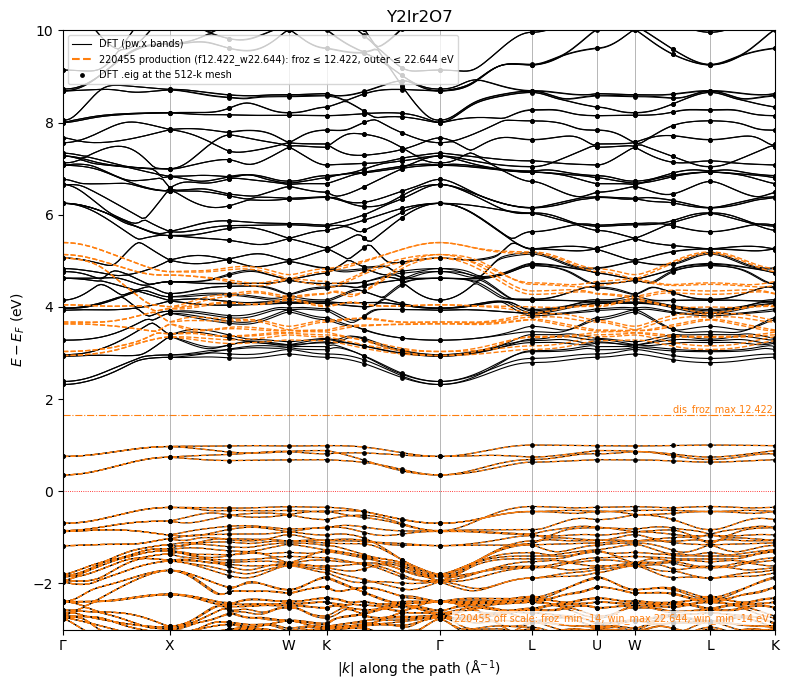

In [3]:
# ---- plot settings
d = yio
E_MIN, E_MAX = -3.0, 10.0          # eV relative to E_F
RUNS = ["220455 production (f12.422_w22.644)"]   # labels of WANNIER to draw, in this order
SHOW_DFT = True                    # pw.x bands (black)
SHOW_MESH_EIG = True               # DFT .eig at the path points on the Wannier mesh (of the first run in RUNS)
SHOW_WINDOWS = True                # each run's frozen (dash-dot) and outer (solid) window edges, in its colour
SHOW_W90_BAND_DAT = False          # Wannier90's own interpolation (<run>/<prefix>_band.dat), thin lines
E_LINES = {}                       # more absolute energies (eV) to mark, {label: E}
FIGSIZE = (8, 7)
SAVE_FIG = DATA / "Y2Ir2O7/windows/f12.422_w22.644_k8/base/bands_dft_wannier.png"   # or None
# ---------------

# ---- draw (nothing below builds or diagonalises a Hamiltonian)
x, e_f = d["distance"], d["e_fermi"]
fig, ax = plt.subplots(figsize=FIGSIZE)
if SHOW_DFT and d["dft"] is not None:
    ax.plot(x, d["dft"].T - e_f, color="black", lw=0.8)
    ax.plot([], [], color="black", lw=0.8, label="DFT (pw.x bands)")
off_scale = []
for i, label in enumerate(RUNS):
    run, color = d["runs"][label], f"C{i + 1}"
    (w_lo, w_hi), (f_lo, f_hi) = run["dis_window"], run["dis_froz_window"]
    ax.plot(x, run["evals"] - e_f, color=color, lw=1.0, ls="--")
    ax.plot([], [], color=color, ls="--", label=f"{label}: froz ≤ {f_hi:g}, outer ≤ {w_hi:g} eV")
    if SHOW_W90_BAND_DAT:                                  # Wannier90's own interpolation, same x convention
        folder = d["wannier"][label]
        band_dat = np.loadtxt(folder / f"{d['prefix']}_band.dat")
        n = len(np.loadtxt(folder / f"{d['prefix']}_band.kpt", skiprows=1))
        ax.plot(band_dat[:n, 0], band_dat[:, 1].reshape(-1, n).T - e_f, color=color, lw=0.5, alpha=0.6)
        ax.plot([], [], color=color, lw=0.5, alpha=0.6, label="  same run, Wannier90 _band.dat")
    if SHOW_WINDOWS:
        outside = []
        for name, value, style in (("froz_max", f_hi, "-."), ("froz_min", f_lo, "-."), ("win_max", w_hi, "-"), ("win_min", w_lo, "-")):
            if E_MIN <= value - e_f <= E_MAX:
                ax.axhline(value - e_f, color=color, lw=0.8, ls=style)
                ax.text(x[-1], value - e_f, f"dis_{name} {value:g} ", ha="right", va="bottom", fontsize=7, color=color)
            else:
                outside.append(f"{name} {value:g}")
        if outside:
            off_scale.append((color, f"{label.split()[0]} off scale: " + ", ".join(outside) + " eV"))
if SHOW_MESH_EIG and RUNS:                                 # DFT .eig at path points that are on the Wannier mesh
    run = d["runs"][RUNS[0]]
    for index, point in enumerate(d["points"]):
        hit = np.flatnonzero(np.abs((run["mesh"] - point + 0.5) % 1.0 - 0.5).max(axis=1) < 1e-6)
        if hit.size:
            ax.scatter(np.full(run["mesh_eig"].shape[1], x[index]), run["mesh_eig"][hit[0]] - e_f, s=6, color="black", zorder=3)
    ax.scatter([], [], s=6, color="black", label=f"DFT .eig at the {len(run['mesh'])}-k mesh")
for name, value in E_LINES.items():
    ax.axhline(value - e_f, color="C9", lw=0.8, ls=":")
    ax.text(x[-1], value - e_f, f"{name} ", ha="right", va="bottom", fontsize=7, color="C9")
for n, (color, text) in enumerate(off_scale):            # window edges outside the energy range
    ax.text(0.99, 0.01 + 0.03 * n, text, transform=ax.transAxes, ha="right", va="bottom", fontsize=7, color=color,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
xticks = [x[i] for i, _ in d["ticks"]]
ax.set_xticks(xticks, [label for _, label in d["ticks"]])
for left, right, a, b in zip(ax.get_xticklabels()[:-1], ax.get_xticklabels()[1:], xticks[:-1], xticks[1:]):
    if b - a < 0.03 * (xticks[-1] - xticks[0]):        # close nodes (MnBi2Te4 P1-F): labels apart
        left.set_ha("right"); right.set_ha("left")
for xt in xticks:
    ax.axvline(xt, color="gray", lw=0.4)
ax.axhline(0, color="red", lw=0.6, ls=":")
ax.legend(loc="upper left", frameon=True, fontsize=7)
ax.set(xlim=(x[0], x[-1]), ylim=(E_MIN, E_MAX), ylabel=r"$E - E_F$ (eV)", xlabel=r"$|k|$ along the path (Å$^{-1}$)",
       title=d["prefix"])
fig.tight_layout()
if SAVE_FIG:
    fig.savefig(SAVE_FIG, dpi=200)
plt.show()